In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/janadarwish/sprints-dataset/employer_partner_requirements.json
/kaggle/input/datasets/janadarwish/sprints-dataset/sprints_cohort_data_2023.csv



# Sprints Employer Partner Analytics: Talent Pipeline Optimization

## 1. Project Overview

### Business Problem
Sprints needs a reliable, data-driven way to evaluate graduates' technical skills, learning progress, and engagement. Employer partners need transparent evidence to identify candidates whose skills match their job requirements.

### Project Objective
This notebook focuses on inspecting, cleaning, and exploring the historical learner assessment dataset to prepare a reliable foundation for talent pipeline analysis and employer recommendations.

### Tools
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn



## 2. Data-Driven Decision-Making Workflow

The project follows these steps:

1. **Define the problem:** Understand employer hiring needs and learner assessment data.
2. **Collect the data:** Load learner assessments and inspect employer requirements.
3. **Assess data quality:** Identify missing values, duplicates, invalid entries, and potential outliers.
4. **Prepare the data:** Clean and validate the dataset using Pandas.
5. **Explore the data:** Analyze learner performance, engagement, and differences across cohorts.
6. **Generate insights:** Identify patterns that may help employers understand the available talent pool.
7. **Support decisions:** Prepare the cleaned dataset for skill engineering, employer compatibility analysis, and interactive visualization.

The findings will be used to inform employer decisions, not to make hiring decisions based on demographic characteristics.


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [3]:
file_path = "/kaggle/input/datasets/janadarwish/sprints-dataset/sprints_cohort_data_2023.csv"

In [4]:
with open(file_path, "r", encoding="utf-8-sig") as file:
    for line_number, line in enumerate(file, start=1):
        if 24 <= line_number <= 27:
            print(line_number, line.rstrip())

24 LRN-1021,2023-Q2-FS,2023-04-10,2023-10-15,Group_D,Full Stack Web Development,84,86,85,89,87,90,88,85,87,91,89,88
25 LRN-1022,2023-Q1-DA,2023-01-15,2023-07-20,Group_B,Advanced Data Analysis,80,85,83,81,84,87,85,82,88,86,84,85
26 LRN-1023,2023-Q2-AI,2023-04-10,,Group_C,AI & Machine Learning,15,45,40,48,50,,,,,,,,
27 LRN-1024,2023-Q3-DA,2023-07-12,2024-01-20,Group_A,Advanced Data Analysis,88,90,92,89,93,88,91,90,92,94,93,91


In [5]:
with open(file_path, "r", encoding="utf-8-sig") as file:
    header = file.readline()

columns = header.strip().split(",")

print("Number of columns:", len(columns))
print("Column names:")

for column in columns:
    print(column)

Number of columns: 18
Column names:
learner_id
cohort_id
enrollment_date
graduation_date
demographic_group
track_name
engagement_score
module_1_score
module_2_score
module_3_score
module_4_score
module_5_score
module_6_score
module_7_score
module_8_score
module_9_score
module_10_score
capstone_score


In [6]:
from io import StringIO

with open(file_path, "r", encoding="utf-8-sig") as file:
    lines = file.readlines()

# Fix the extra commas at the end of line 26
lines[25] = lines[25].rstrip("\r\n").rstrip(",") + "\n"

# Read the corrected data
df = pd.read_csv(StringIO("".join(lines)))

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (26, 18)


,learner_id,cohort_id,enrollment_date,graduation_date,demographic_group,track_name,engagement_score,module_1_score,module_2_score,module_3_score,module_4_score,module_5_score,module_6_score,module_7_score,module_8_score,module_9_score,module_10_score,capstone_score
0,LRN-1001,2023-Q1-DA,2023-01-15,2023-07-20,Group_A,Advanced Data Analysis,85.0,90,88.0,92.0,85,89.0,94.0,88.0,91.0,95.0,90.0,93.0
1,LRN-1002,2023-Q1-DA,2023-01-15,2023-07-20,Group_B,Advanced Data Analysis,999.0,70,75.0,NaN,65,80.0,77.0,81.0,72.0,68.0,74.0,76.0
2,LRN-1003,2023-Q2-AI,2023-04-10,2023-10-15,Group_A,AI & Machine Learning,92.0,95,96.0,91.0,98,94.0,99.0,90.0,92.0,95.0,97.0,96.0
3,LRN-1004,2023-Q1-FS,2023-01-15,2023-07-20,Group_C,Full Stack Web Development,45.0,60,55.0,58.0,62,59.0,61.0,65.0,54.0,55.0,60.0,58.0
4,LRN-1001,2023-Q1-DA,2023-01-15,2023-07-20,Group_A,Advanced Data Analysis,85.0,90,88.0,92.0,85,89.0,94.0,88.0,91.0,95.0,90.0,93.0


In [7]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 26
Number of columns: 18


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26 entries, 0 to 25
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   learner_id         26 non-null     object 
 1   cohort_id          26 non-null     object 
 2   enrollment_date    26 non-null     object 
 3   graduation_date    24 non-null     object 
 4   demographic_group  26 non-null     object 
 5   track_name         26 non-null     object 
 6   engagement_score   25 non-null     float64
 7   module_1_score     26 non-null     int64  
 8   module_2_score     25 non-null     float64
 9   module_3_score     25 non-null     float64
 10  module_4_score     26 non-null     int64  
 11  module_5_score     24 non-null     float64
 12  module_6_score     23 non-null     float64
 13  module_7_score     24 non-null     float64
 14  module_8_score     23 non-null     float64
 15  module_9_score     23 non-null     float64
 16  module_10_score    23 non-nu

In [9]:
df.isnull().sum()

learner_id           0
cohort_id            0
enrollment_date      0
graduation_date      2
demographic_group    0
track_name           0
engagement_score     1
module_1_score       0
module_2_score       1
module_3_score       1
module_4_score       0
module_5_score       2
module_6_score       3
module_7_score       2
module_8_score       3
module_9_score       3
module_10_score      3
capstone_score       3
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(2)

In [11]:
duplicate_rows = df[df.duplicated(keep=False)]

display(duplicate_rows)

,learner_id,cohort_id,enrollment_date,graduation_date,demographic_group,track_name,engagement_score,module_1_score,module_2_score,module_3_score,module_4_score,module_5_score,module_6_score,module_7_score,module_8_score,module_9_score,module_10_score,capstone_score
0,LRN-1001,2023-Q1-DA,2023-01-15,2023-07-20,Group_A,Advanced Data Analysis,85.0,90,88.0,92.0,85,89.0,94.0,88.0,91.0,95.0,90.0,93.0
4,LRN-1001,2023-Q1-DA,2023-01-15,2023-07-20,Group_A,Advanced Data Analysis,85.0,90,88.0,92.0,85,89.0,94.0,88.0,91.0,95.0,90.0,93.0
8,LRN-1008,2023-Q2-FS,2023-04-10,2023-10-15,Group_C,Full Stack Web Development,88.0,92,90.0,85.0,89,94.0,91.0,88.0,93.0,95.0,90.0,91.0
12,LRN-1008,2023-Q2-FS,2023-04-10,2023-10-15,Group_C,Full Stack Web Development,88.0,92,90.0,85.0,89,94.0,91.0,88.0,93.0,95.0,90.0,91.0


In [12]:
score_columns = [
    "engagement_score",
    "module_1_score",
    "module_2_score",
    "module_3_score",
    "module_4_score",
    "module_5_score",
    "module_6_score",
    "module_7_score",
    "module_8_score",
    "module_9_score",
    "module_10_score",
    "capstone_score"
]

display(df[score_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
engagement_score,25.0,162.080000,336.629361,-20.0,65.00,84.0,89.00,1500.0
module_1_score,26.0,80.461538,15.375905,40.0,71.25,85.5,90.75,98.0
module_2_score,25.0,79.880000,15.226950,40.0,75.00,85.0,90.00,97.0
module_3_score,25.0,80.960000,14.959612,42.0,79.00,85.0,91.00,98.0
module_4_score,26.0,80.653846,14.639514,38.0,75.25,85.0,89.75,99.0
module_5_score,24.0,85.708333,10.343993,59.0,80.75,89.0,94.00,97.0
module_6_score,23.0,85.913043,10.348092,61.0,81.50,88.0,93.00,99.0
module_7_score,24.0,83.125000,9.246915,59.0,80.25,86.5,89.00,95.0
module_8_score,23.0,85.565217,10.116710,54.0,82.50,88.0,92.00,97.0
module_9_score,23.0,87.260870,10.724727,55.0,83.00,91.0,95.00,99.0


In [13]:
display(
    df.loc[
        (df["engagement_score"] < 0) |
        (df["engagement_score"] > 100),
        ["learner_id", "engagement_score"]
    ]
)

,learner_id,engagement_score
1,LRN-1002,999.0
6,LRN-1006,-20.0
13,LRN-1012,1500.0
21,LRN-1020,-5.0


In [14]:
clean_df = df.copy()

invalid_engagement = (
    (clean_df["engagement_score"] < 0) |
    (clean_df["engagement_score"] > 100)
)

clean_df.loc[invalid_engagement, "engagement_score"] = np.nan

In [15]:
clean_df = df.copy()

invalid_engagement = (
    (clean_df["engagement_score"] < 0) |
    (clean_df["engagement_score"] > 100)
)

clean_df.loc[invalid_engagement, "engagement_score"] = np.nan

print("Invalid engagement values after cleaning:")
print(clean_df["engagement_score"].isna().sum())

Invalid engagement values after cleaning:
5


In [16]:
duplicate_rows = clean_df[clean_df.duplicated(keep=False)]
display(duplicate_rows)

,learner_id,cohort_id,enrollment_date,graduation_date,demographic_group,track_name,engagement_score,module_1_score,module_2_score,module_3_score,module_4_score,module_5_score,module_6_score,module_7_score,module_8_score,module_9_score,module_10_score,capstone_score
0,LRN-1001,2023-Q1-DA,2023-01-15,2023-07-20,Group_A,Advanced Data Analysis,85.0,90,88.0,92.0,85,89.0,94.0,88.0,91.0,95.0,90.0,93.0
4,LRN-1001,2023-Q1-DA,2023-01-15,2023-07-20,Group_A,Advanced Data Analysis,85.0,90,88.0,92.0,85,89.0,94.0,88.0,91.0,95.0,90.0,93.0
8,LRN-1008,2023-Q2-FS,2023-04-10,2023-10-15,Group_C,Full Stack Web Development,88.0,92,90.0,85.0,89,94.0,91.0,88.0,93.0,95.0,90.0,91.0
12,LRN-1008,2023-Q2-FS,2023-04-10,2023-10-15,Group_C,Full Stack Web Development,88.0,92,90.0,85.0,89,94.0,91.0,88.0,93.0,95.0,90.0,91.0


In [17]:
clean_df = clean_df.drop_duplicates()

print("Shape after removing duplicates:", clean_df.shape)
print("Remaining duplicates:", clean_df.duplicated().sum())

Shape after removing duplicates: (24, 18)
Remaining duplicates: 0


In [18]:
missing_values = clean_df.isnull().sum()

print("Missing values in each column:")
print(missing_values[missing_values > 0])

print("\nTotal missing values:", clean_df.isnull().sum().sum())

Missing values in each column:
graduation_date     2
engagement_score    5
module_2_score      1
module_3_score      1
module_5_score      2
module_6_score      3
module_7_score      2
module_8_score      3
module_9_score      3
module_10_score     3
capstone_score      3
dtype: int64

Total missing values: 28


In [19]:
missing_rows = clean_df[clean_df.isnull().any(axis=1)]

display(
    missing_rows[
        [
            "learner_id",
            "graduation_date",
            "engagement_score",
            "module_1_score",
            "module_5_score",
            "module_10_score",
            "capstone_score"
        ]
    ]
)

,learner_id,graduation_date,engagement_score,module_1_score,module_5_score,module_10_score,capstone_score
1,LRN-1002,2023-07-20,NaN,70,80.0,74.0,76.0
5,LRN-1005,2023-10-15,78.0,80,81.0,84.0,85.0
6,LRN-1006,2024-01-20,NaN,88,92.0,94.0,90.0
7,LRN-1007,NaN,30.0,40,NaN,NaN,NaN
11,LRN-1011,2023-10-15,82.0,85,88.0,88.0,87.0
13,LRN-1012,2023-07-20,NaN,88,92.0,94.0,90.0
15,LRN-1014,2023-10-15,NaN,85,89.0,88.0,86.0
17,LRN-1016,2023-07-20,55.0,60,61.0,NaN,NaN
21,LRN-1020,2024-01-20,NaN,68,76.0,75.0,74.0
24,LRN-1023,NaN,15.0,45,NaN,NaN,NaN


In [20]:
date_columns = ["enrollment_date", "graduation_date"]

for column in date_columns:
    clean_df[column] = pd.to_datetime(
        clean_df[column],
        errors="coerce"
    )

clean_df[date_columns].info()

<class 'pandas.core.frame.DataFrame'>
Index: 24 entries, 0 to 25
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   enrollment_date  24 non-null     datetime64[ns]
 1   graduation_date  22 non-null     datetime64[ns]
dtypes: datetime64[ns](2)
memory usage: 576.0 bytes


In [21]:
score_columns = [
    f"module_{i}_score" for i in range(1, 11)
] + ["capstone_score"]

for column in score_columns:
    invalid_scores = clean_df[
        (clean_df[column] < 0) | (clean_df[column] > 100)
    ]

    if not invalid_scores.empty:
        print(f"\n{column}:")
        display(invalid_scores[["learner_id", column]])

In [22]:
# Summary statistics for scores and engagement
numeric_columns = ["engagement_score"] + score_columns

display(clean_df[numeric_columns].describe().round(2))

,engagement_score,module_1_score,module_2_score,module_3_score,module_4_score,module_5_score,module_6_score,module_7_score,module_8_score,module_9_score,module_10_score,capstone_score
count,19.00,24.00,23.00,23.00,24.00,22.00,21.00,22.00,21.00,21.00,21.00,21.00
mean,73.95,79.58,79.09,80.30,80.12,85.18,85.29,82.68,84.95,86.52,86.24,86.05
std,22.51,15.70,15.64,15.41,15.13,10.64,10.62,9.55,10.39,10.95,9.97,9.85
min,15.00,40.00,40.00,42.00,38.00,59.00,61.00,59.00,54.00,55.00,60.00,58.00
25%,68.50,70.00,73.50,77.00,74.25,80.25,81.00,78.75,80.00,82.00,82.00,81.00
50%,82.00,85.00,83.00,85.00,84.50,88.50,86.00,85.50,88.00,91.00,89.00,88.00
75%,88.50,90.25,90.00,90.00,90.00,93.50,92.00,89.00,92.00,95.00,94.00,92.00
max,95.00,98.00,97.00,98.00,99.00,97.00,99.00,95.00,97.00,99.00,98.00,99.00


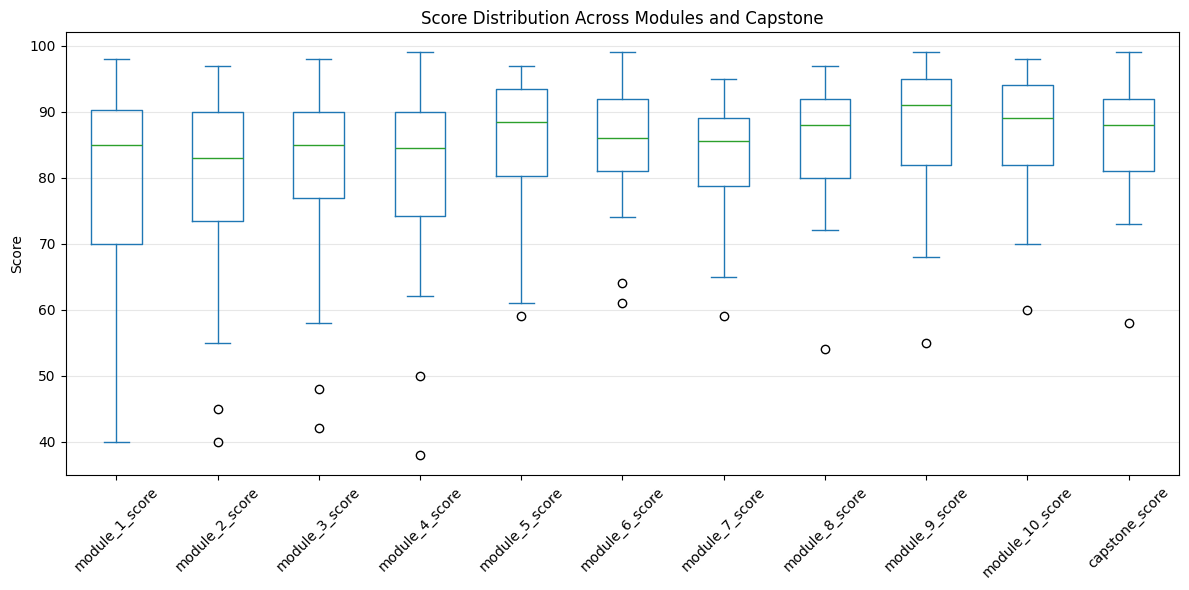

In [23]:
clean_df[score_columns].plot(
    kind="box",
    figsize=(12, 6)
)

plt.title("Score Distribution Across Modules and Capstone")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Initial Exploratory Data Analysis (EDA)

### Key Findings
- The dataset contains 24 records and 18 columns after removing duplicate rows.
- Four invalid engagement scores were converted to missing values because they were outside the expected 0–100 range.
- Missing values remain in several columns and will be handled according to their meaning and analytical purpose.
- Module scores generally show higher median values in later modules compared with the earlier modules.
- The median score increases from 85 in Module 1 to 91 in Module 9, then decreases to 89 in Module 10.
- The median capstone score is 88, indicating generally strong capstone performance among learners with available scores.

### Data Quality Notes
- Two duplicate records were removed.
- Enrollment and graduation dates were converted to datetime format.
- All module and capstone scores were verified to be within the 0–100 range.
- Missing values were retained rather than filled with arbitrary values.

In [24]:
clean_df.to_csv("sprints_cohort_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Final shape:", clean_df.shape)

Cleaned dataset saved successfully!
Final shape: (24, 18)


In [25]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    if "employer_partner_requirements.json" in files:
        print(os.path.join(root, "employer_partner_requirements.json"))

/kaggle/input/datasets/janadarwish/sprints-dataset/employer_partner_requirements.json


In [26]:
print(df.columns.tolist())

['learner_id', 'cohort_id', 'enrollment_date', 'graduation_date', 'demographic_group', 'track_name', 'engagement_score', 'module_1_score', 'module_2_score', 'module_3_score', 'module_4_score', 'module_5_score', 'module_6_score', 'module_7_score', 'module_8_score', 'module_9_score', 'module_10_score', 'capstone_score']


In [27]:
module_columns = [f"module_{i}_score" for i in range(1, 11)]

module_scores_long = df.melt(
    id_vars=["learner_id", "cohort_id"],
    value_vars=module_columns,
    var_name="module",
    value_name="score"
)

module_scores_long["module_number"] = (
    module_scores_long["module"].str.extract(r"(\d+)").astype(int)
)

module_scores_long = module_scores_long.sort_values(
    ["learner_id", "module_number"]
)

display(module_scores_long.head(10))

# Average score for each module
module_progression = (
    module_scores_long.groupby("module_number")["score"]
    .mean()
    .reset_index()
)

display(module_progression)

,learner_id,cohort_id,module,score,module_number
0,LRN-1001,2023-Q1-DA,module_1_score,90.0,1
4,LRN-1001,2023-Q1-DA,module_1_score,90.0,1
26,LRN-1001,2023-Q1-DA,module_2_score,88.0,2
30,LRN-1001,2023-Q1-DA,module_2_score,88.0,2
52,LRN-1001,2023-Q1-DA,module_3_score,92.0,3
56,LRN-1001,2023-Q1-DA,module_3_score,92.0,3
78,LRN-1001,2023-Q1-DA,module_4_score,85.0,4
82,LRN-1001,2023-Q1-DA,module_4_score,85.0,4
104,LRN-1001,2023-Q1-DA,module_5_score,89.0,5
108,LRN-1001,2023-Q1-DA,module_5_score,89.0,5


,module_number,score
0,1,80.461538
1,2,79.880000
2,3,80.960000
3,4,80.653846
4,5,85.708333
5,6,85.913043
6,7,83.125000
7,8,85.565217
8,9,87.260870
9,10,86.565217


In [28]:
module_columns = [f"module_{i}_score" for i in range(1, 11)]

# Calculate mastery from the available module scores
df["Skill_Mastery_Index"] = df[module_columns].mean(axis=1)

# Summary by cohort
cohort_summary = (
    df.groupby("cohort_id")
    .agg(
        learner_count=("learner_id", "nunique"),
        median_mastery=("Skill_Mastery_Index", "median"),
        median_engagement=("engagement_score", "median")
    )
    .reset_index()
)

display(cohort_summary)

# Summary by cohort and demographic group
demographic_summary = (
    df.groupby(["cohort_id", "demographic_group"])
    .agg(
        learner_count=("learner_id", "nunique"),
        median_mastery=("Skill_Mastery_Index", "median"),
        median_engagement=("engagement_score", "median")
    )
    .reset_index()
)

display(demographic_summary)

# Summary by cohort and track
track_summary = (
    df.groupby(["cohort_id", "track_name"])
    .agg(
        learner_count=("learner_id", "nunique"),
        median_mastery=("Skill_Mastery_Index", "median"),
        median_engagement=("engagement_score", "median")
    )
    .reset_index()
)

display(track_summary)

,cohort_id,learner_count,median_mastery,median_engagement
0,2023-Q1-AI,2,92.800,797.0
1,2023-Q1-DA,6,78.000,80.0
2,2023-Q1-FS,1,58.900,45.0
3,2023-Q2-AI,2,70.225,53.5
4,2023-Q2-DA,3,86.000,82.0
5,2023-Q2-FS,3,89.200,88.0
6,2023-Q3-AI,2,95.250,93.0
7,2023-Q3-DA,4,81.000,30.0
8,2023-Q3-FS,1,80.700,77.0


,cohort_id,demographic_group,learner_count,median_mastery,median_engagement
0,2023-Q1-AI,Group_A,1,96.700000,94.0
1,2023-Q1-AI,Group_C,1,88.900000,1500.0
2,2023-Q1-DA,Group_A,2,90.200000,85.0
3,2023-Q1-DA,Group_B,2,79.027778,539.5
4,2023-Q1-DA,Group_C,1,61.285714,55.0
5,2023-Q1-DA,Group_D,1,78.000000,72.0
6,2023-Q1-FS,Group_C,1,58.900000,45.0
7,2023-Q2-AI,Group_A,1,94.700000,92.0
8,2023-Q2-AI,Group_C,1,45.750000,15.0
9,2023-Q2-DA,Group_A,1,91.600000,89.0


,cohort_id,track_name,learner_count,median_mastery,median_engagement
0,2023-Q1-AI,AI & Machine Learning,2,92.800,797.0
1,2023-Q1-DA,Advanced Data Analysis,6,78.000,80.0
2,2023-Q1-FS,Full Stack Web Development,1,58.900,45.0
3,2023-Q2-AI,AI & Machine Learning,2,70.225,53.5
4,2023-Q2-DA,Advanced Data Analysis,3,86.000,82.0
5,2023-Q2-FS,Full Stack Web Development,3,89.200,88.0
6,2023-Q3-AI,AI & Machine Learning,2,95.250,93.0
7,2023-Q3-DA,Advanced Data Analysis,4,81.000,30.0
8,2023-Q3-FS,Full Stack Web Development,1,80.700,77.0


In [29]:

# Select the 10 module score columns
score_columns = [f"module_{i}_score" for i in range(1, 11)]
scores = df[score_columns].to_numpy(dtype=float)

# Example weights: later modules receive slightly higher importance
weights = np.array([1, 1, 1, 1, 1.1, 1.1, 1.2, 1.2, 1.3, 1.3])

# Ignore missing scores and adjust weights for each learner
valid_scores = ~np.isnan(scores)
weighted_scores = np.nansum(scores * weights, axis=1)
available_weights = np.sum(valid_scores * weights, axis=1)

df["Weighted_Skill_Mastery_Index"] = np.divide(
    weighted_scores,
    available_weights,
    out=np.full(len(df), np.nan, dtype=float),
    where=available_weights != 0
)

display(
    df[["learner_id", "Skill_Mastery_Index",
        "Weighted_Skill_Mastery_Index"]].head()
)

,learner_id,Skill_Mastery_Index,Weighted_Skill_Mastery_Index
0,LRN-1001,90.200000,90.321429
1,LRN-1002,73.555556,73.617647
2,LRN-1003,94.700000,94.669643
3,LRN-1004,58.900000,58.866071
4,LRN-1001,90.200000,90.321429


In [30]:

import json

# Load employer requirements
requirements_path = (
    "/kaggle/input/datasets/janadarwish/"
    "sprints-dataset/employer_partner_requirements.json"
)

with open(requirements_path, "r", encoding="utf-8") as file:
    jobs = pd.DataFrame(json.load(file)["employer_requirements"])

# Learner profiles: the 10 module scores
score_columns = [f"module_{i}_score" for i in range(1, 11)]
learner_profiles = df[score_columns].to_numpy(dtype=float)

# Fill missing scores using each module's mean
module_means = np.nanmean(learner_profiles, axis=0)
learner_profiles = np.where(
    np.isnan(learner_profiles),
    module_means[None, :],
    learner_profiles
)

# Employer profiles: repeat each role's minimum assessment threshold
# across the 10 modules as a threshold-based proxy
job_thresholds = jobs["minimum_assessment_threshold"].to_numpy(dtype=float)
employer_profiles = np.repeat(
    job_thresholds[:, None],
    len(score_columns),
    axis=1
)

# Normalize profiles and calculate cosine similarity using matrix multiplication
learner_norms = np.linalg.norm(learner_profiles, axis=1, keepdims=True)
employer_norms = np.linalg.norm(employer_profiles, axis=1, keepdims=True)

learner_normalized = learner_profiles / np.maximum(learner_norms, 1e-12)
employer_normalized = employer_profiles / np.maximum(employer_norms, 1e-12)

similarity_matrix = learner_normalized @ employer_normalized.T
similarity_matrix = np.clip(similarity_matrix * 100, 0, 100)

similarity_results = pd.DataFrame(
    similarity_matrix,
    index=df["learner_id"],
    columns=jobs["role_id"]
)

display(similarity_results.iloc[:5, :5])

role_id,REQ-1001,REQ-1002,REQ-1003,REQ-1004,REQ-1005
learner_id,,,,,
LRN-1001,99.951118,99.951118,99.951118,99.951118,99.951118
LRN-1002,99.747724,99.747724,99.747724,99.747724,99.747724
LRN-1003,99.955372,99.955372,99.955372,99.955372,99.955372
LRN-1004,99.843416,99.843416,99.843416,99.843416,99.843416
LRN-1001,99.951118,99.951118,99.951118,99.951118,99.951118


In [31]:
# Learner scores: (number of learners,)
learner_scores = df["Weighted_Skill_Mastery_Index"].to_numpy(dtype=float)

# Employer requirements: (number of roles,)
thresholds = jobs["minimum_assessment_threshold"].to_numpy(dtype=float)
priorities = jobs["priority_weight"].to_numpy(dtype=float)

# Matrix: learners x roles
score_matrix = learner_scores[:, None]
threshold_matrix = thresholds[None, :]
priority_matrix = priorities[None, :]

# How far each learner is above/below each role's threshold
threshold_gap = score_matrix - threshold_matrix

# Eligibility based on the minimum required score
eligible_matrix = threshold_gap >= 0

# Threshold-based match score: 100 if eligible, proportional score otherwise
match_score_matrix = np.clip(
    score_matrix / threshold_matrix * 100,
    0,
    100
)

# Prioritize roles using employer priority weights
priority_score_matrix = match_score_matrix * priority_matrix

# Flatten matrices into a table
matching_results = pd.DataFrame({
    "learner_id": np.repeat(df["learner_id"].to_numpy(), len(jobs)),
    "role_id": np.tile(jobs["role_id"].to_numpy(), len(df)),
    "job_title": np.tile(jobs["job_title"].to_numpy(), len(df)),
    "weighted_mastery": np.repeat(learner_scores, len(jobs)),
    "minimum_threshold": np.tile(thresholds, len(df)),
    "priority_weight": np.tile(priorities, len(df)),
    "threshold_gap": threshold_gap.ravel(),
    "meets_threshold": eligible_matrix.ravel(),
    "match_score": match_score_matrix.ravel(),
    "priority_score": priority_score_matrix.ravel()
})

# Show the top 3 eligible roles for each learner
top_matches = (
    matching_results[matching_results["meets_threshold"]]
    .sort_values(
        ["learner_id", "priority_score"],
        ascending=[True, False]
    )
    .groupby("learner_id")
    .head(3)
)

display(top_matches.head(15))

,learner_id,role_id,job_title,weighted_mastery,minimum_threshold,priority_weight,threshold_gap,meets_threshold,match_score,priority_score
8,LRN-1001,REQ-1009,Data Engineer I,90.321429,90.0,0.95,0.321429,True,100.0,95.0
208,LRN-1001,REQ-1009,Data Engineer I,90.321429,90.0,0.95,0.321429,True,100.0,95.0
35,LRN-1001,REQ-1036,Cybersecurity Data Analyst,90.321429,90.0,0.92,0.321429,True,100.0,92.0
60,LRN-1002,REQ-1011,Customer Insights Analyst,73.617647,72.0,0.50,1.617647,True,100.0,50.0
86,LRN-1002,REQ-1037,Market Research Analyst,73.617647,71.0,0.50,2.617647,True,100.0,50.0
65,LRN-1002,REQ-1016,Junior Python Developer (Data),73.617647,70.0,0.45,3.617647,True,100.0,45.0
109,LRN-1003,REQ-1010,Junior Quantitative Analyst,94.669643,94.0,0.98,0.669643,True,100.0,98.0
144,LRN-1003,REQ-1045,Recommendation Systems Engineer,94.669643,94.0,0.96,0.669643,True,100.0,96.0
101,LRN-1003,REQ-1002,Data Scientist I,94.669643,92.0,0.95,2.669643,True,100.0,95.0
257,LRN-1005,REQ-1008,Healthcare Data Analyst,83.138614,82.0,0.80,1.138614,True,100.0,80.0


In [32]:
# Remove duplicate learner records
df_matching = df.drop_duplicates(
    subset="learner_id",
    keep="first"
).copy()

# Prepare learner and employer data
learner_scores = df_matching[
    "Weighted_Skill_Mastery_Index"
].to_numpy(dtype=float)

thresholds = jobs["minimum_assessment_threshold"].to_numpy(dtype=float)
priorities = jobs["priority_weight"].to_numpy(dtype=float)

# Calculate learner-role comparisons using NumPy broadcasting
threshold_gap = learner_scores[:, None] - thresholds[None, :]
eligible = threshold_gap >= 0

match_score = np.clip(
    learner_scores[:, None] / thresholds[None, :] * 100,
    0,
    100
)

priority_score = match_score * priorities[None, :]

# Build the results table
matching_results = pd.DataFrame({
    "learner_id": np.repeat(
        df_matching["learner_id"].to_numpy(), len(jobs)
    ),
    "role_id": np.tile(jobs["role_id"].to_numpy(), len(df_matching)),
    "job_title": np.tile(jobs["job_title"].to_numpy(), len(df_matching)),
    "weighted_mastery": np.repeat(learner_scores, len(jobs)),
    "minimum_threshold": np.tile(thresholds, len(df_matching)),
    "priority_weight": np.tile(priorities, len(df_matching)),
    "threshold_gap": threshold_gap.ravel(),
    "meets_threshold": eligible.ravel(),
    "match_score": match_score.ravel(),
    "priority_score": priority_score.ravel()
})

top_matches = (
    matching_results[matching_results["meets_threshold"]]
    .sort_values(
        ["learner_id", "priority_score"],
        ascending=[True, False]
    )
    .groupby("learner_id")
    .head(3)
)

print("Unique learners:", df_matching["learner_id"].nunique())
print("Total comparisons:", len(matching_results))
display(top_matches.head(15))

Unique learners: 24
Total comparisons: 1200


,learner_id,role_id,job_title,weighted_mastery,minimum_threshold,priority_weight,threshold_gap,meets_threshold,match_score,priority_score
8,LRN-1001,REQ-1009,Data Engineer I,90.321429,90.0,0.95,0.321429,True,100.0,95.0
35,LRN-1001,REQ-1036,Cybersecurity Data Analyst,90.321429,90.0,0.92,0.321429,True,100.0,92.0
0,LRN-1001,REQ-1001,Junior Data Analyst,90.321429,85.0,0.90,5.321429,True,100.0,90.0
60,LRN-1002,REQ-1011,Customer Insights Analyst,73.617647,72.0,0.50,1.617647,True,100.0,50.0
86,LRN-1002,REQ-1037,Market Research Analyst,73.617647,71.0,0.50,2.617647,True,100.0,50.0
65,LRN-1002,REQ-1016,Junior Python Developer (Data),73.617647,70.0,0.45,3.617647,True,100.0,45.0
109,LRN-1003,REQ-1010,Junior Quantitative Analyst,94.669643,94.0,0.98,0.669643,True,100.0,98.0
144,LRN-1003,REQ-1045,Recommendation Systems Engineer,94.669643,94.0,0.96,0.669643,True,100.0,96.0
101,LRN-1003,REQ-1002,Data Scientist I,94.669643,92.0,0.95,2.669643,True,100.0,95.0
207,LRN-1005,REQ-1008,Healthcare Data Analyst,83.138614,82.0,0.80,1.138614,True,100.0,80.0


In [33]:
# Save learner-job matching results
matching_results.to_csv(
    "learner_job_matching_results.csv",
    index=False
)

top_matches.to_csv(
    "top_learner_job_matches.csv",
    index=False
)

print("Files saved successfully:")
print("- learner_job_matching_results.csv")
print("- top_learner_job_matches.csv")

Files saved successfully:
- learner_job_matching_results.csv
- top_learner_job_matches.csv
